In [1]:
############################################################
# Headers

import os
import re
import configparser
from   glob import glob

from scipy.optimize    import curve_fit, fsolve, root
from scipy.interpolate import interp1d, interp2d, interpn

from   pylab      import *
import matplotlib
from   matplotlib.colors import Normalize, LogNorm

############################################################
# Constants

h      = 6.62607e-27;   # CGS Planctk constant
kb     = 1.38065e-16;   # CGS Boltzmann constant
eV     = 1.60218e-12;   # CGS eV
c      = 2.99792458e10; # CGS speed of light
q_e    = 4.80321e-10;   # CGS electron charge
me     = 9.1094e-28;    # CGS electron mass;
mp     = 1.67262e-24;   # CGS proton mass;
NA     = 6.022141e23    # Avogadro constant
ma     = 1 / NA;        # Atomic mass unit
AU     = 1.49598e13     # Astronomical Unit in cm
yr     = 3.1536e7       # 1 yr in sec
G      = 6.6742831e-8   # CGS graviational constant
sig_sb = 5.6704e-5      # Stefan-Boltzmann
yr     = 365. * 86400.; # Year in secons

modot  = 1.9891e33;     # Solar mass
rodot  = 6.96e10;       # Solar radius
lodot  = 3.828e33;      # Solar luminosity
mearth = 5.9742e27      # Earth mass
rearth = 6.37814e8;     # Earth Radius

############################################################

In [2]:
############################################################
# Basic chemistry functions;
##############################
elem_data = {  };
with open( 'elem_table.txt' ) as f:
    for line in f.readlines(   ) :
        l = line.strip(  ).split(  );
        elem_data[ l[ 1 ] ] \
            = ( int( l[ 0 ] ), int  ( l[ 2 ] )  ,
                int( l[ 3 ] ), float( l[ 4 ] ) );
#

def species_to_elem( s ):
    if s == 'e-' or 'Gr' in s:
        return {  };
    #
    pe   = re.compile( r'[A-Z][a-z]*(?=\d*)' );
    pd   = re.compile( r'^\d+' );
    res  = { 'charge' : 0 };
    if '+' in s:
        np = s.split( '+' )[ 1 ];
        res[ 'charge' ] += 1 if len( np ) == 0 else int( np )
    if '-' in s:
        nn = s.split( '-' )[ 1 ];
        res[ 'charge' ] -= 1 if len( nn ) == 0 else int( nn )
    #
    s = s.replace( '+', '' );
    s = s.replace( '-', '' );
    while s != '':
        e = pe.search( s );
        e = e.group(  );
        s = s.replace( e, '', 1 );
        d = pd.search( s );
        if d != None:
            d = d.group(  );
            s = s.replace( d, '', 1 );
        else:
            d = '1';
        #
        if not e in res:
            res[ e ]  = int( d );
        else:
            res[ e ] += int( d );
        #
    #
    return res;
#
############################################################

In [3]:
############################################################
# Convert the format of reaction database
##############################
cps = configparser.ConfigParser(  );
cps . optionxform = str
photon_reac_raw = dict(  );

##############################
# 2-Body reactions

with open( 'RATE_K.txt', 'r' ) as f:
    for l in f.readlines(  ):
        if l.strip(  )[ 0 ] == '#':
            continue;
        ll   = l.split( ':' );
        reac = [ 'PHOTON' if s in [ 'CRP', 'CRPHOT' ]
                 else s for s in ll[ 2 : 4 ] ];
        prod = [ '' if s == 'PHOTON'
                 else s for s in ll[ 4 : 8 ] ];
        if 'PHOTON' in reac:
            continue;
        
        ldic = {  };
        ldic[ 'rate_type ' ] = 'ARR';
        ldic[ 'reactants ' ] = ' '.join( reac );
        ldic[ 'products  ' ] = ' '.join( prod );
        ldic[ 'parameters' ] = ' '.join( ll[  9 : 12 ] );
        ldic[ 'T_lim     ' ] = ' '.join( ll[ 12 : 14 ] );
        ldic[ 'comments  ' ] = ';'.join( ll[    :  2 ] +\
                                         ll[ 14 : -1 ] );
        ldic[ 'parameters' ] = ' ';
        for i, sf in enumerate( ll[ 9 : 12 ] ):
            ldic[ 'parameters' ] += ' %f ' % \
            ( float( sf ) * ( 1 if i > 0 else NA ) );
        if 'e-' in ldic[ 'reactants ' ] and not\
           'e-' in ldic[ 'products  ' ]:
            # Draine (2011), eq. (27.23)
            enes = [ 0, 0, 0.0416, 1 ];
            enes[ 1 ] = -0.684 - 0.0416 * log( 1e4 )
            ldic[ 'energy    ' ] = ' '.join\
                ( '%0.2e' % s for s in enes );
        #
        cps[ 'reaction_%06d' % int( ll[ 0 ] ) ]  = ldic;
    #
#
cps[ 'comments' ] = { 'general_std' : 'UMIST2012',
                      'A_rescaling' : 'A * NA' }
with open( 'reaction_umist.dat', 'w' ) as f:
    cps.write( f );
###########################################################

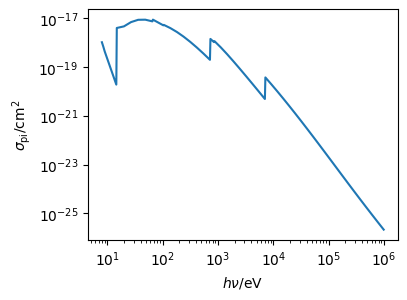

In [8]:
############################################################
# Photoionization cross section
# See Verner et al. (1996), ApJ 465 487
##############################

class sigma_pi:
    def __init__( self, file_name = 'photoionize.txt' ):
        self.dat = loadtxt( file_name );
        self.z   = self.dat.T[ 1 ]; # Nuclear charges
        self.n_e = self.dat.T[ 2 ]; # Num of electrons
        self.n   = self.dat.T[ 3 ]; # Principal quantum #
        self.l   = self.dat.T[ 4 ]; # Angular   quantum #
        self.find_idx = {  };
        for i in range( len( self.z ) ):
            label = ( self.z[ i ], self.n_e[ i ] );
            if  not label in self.find_idx:
                self.find_idx[ label ] = [   ];
            self.find_idx[ label ].append( i );
        #
        return;
    #
    def __call__( self, hv, z, charge = 0 ):
        n_e = z - charge;
        if  not hasattr( hv, '__len__' ):
            hv = [ hv ];
        if  type ( hv ).__module__ != 'numpy':
            hv = array  ( hv );
        res = zeros( len( hv ) );
        dat =  array( [ self.dat[ i ] for i in
                        self.find_idx[ ( z, n_e ) ] ] );
        for j, line in enumerate( dat ):
            id, z, n_e, n, l, e_th, e_0, sigma_0, \
                y_a, P, y_w = line;
            y    = hv / e_0
            Q    = 5.5 + l - 0.5 * P;
            fy   = ( ( y - 1 )**2 + y_w**2 ) * y**( -Q ) \
                 * ( 1 + sqrt( y / y_a ) )**( -P );
            res += fy * sigma_0 * 1e-18 * ( hv > e_th )
        #
        if  len ( res ) < 2:
            res = res [ 0 ];
        return res;
    #

    def get_sigma_table( self, z, charge = 0, n_hv = 50,
                         hv_max = 1e6 ):
        n_e = z - charge;
        dat = array( [ self.dat[ i ] for i in
                       self.find_idx[ ( z, n_e ) ] ] );
        lnhv_th  = log( array\
               ( [ l[ 5 ] for l in dat ] + [ hv_max ] ) );
        d_lnhv   = lnhv_th[ 1 : ] - lnhv_th[ : -1 ];
        dn_dlnhv = n_hv / ( lnhv_th[ -1 ] - lnhv_th[ 0 ] );
        hv       = [  ];
        for i in arange( len( lnhv_th ) - 1 ) + 1:
            n_s = int( maximum\
                     ( d_lnhv[ i - 1 ] * dn_dlnhv, 2 ) );
            lnhv_s = linspace( lnhv_th[ i - 1 ] + 1e-2,
                               lnhv_th[ i ] - 1e-2, n_s );
            hv.append( exp( lnhv_s ) )
        #
        hv = concatenate( hv );
        hv = concatenate\
            ( ( [ hv[ 0 ] + 1e-3, hv[ 0 ] + 1e-2,
                  hv[ 0 ] + 1e-1, hv[ 0 ] + 2e-1,
                  hv[ 0 ] + 5e-1, hv[ 0 ] + 1  ],
                  hv[ 1 : ] ) );
        return hv, self.__call__( hv, z, charge );
    #

    def get_sigma_table_sp\
        ( self, sp, n_hv = 30, hv_max = 1e4 ):
        reac_elem = species_to_elem( sp );
        hv_min    = hv_max * 10;
        hv_min_ie = -1;
        hv_all    = [  ];
        sig_all   = [  ];
        charge    = reac_elem[ 'charge' ];
        for e, n in reac_elem.items(  ):
            if 'charge' == e:
                continue;
            #
            z     = elem_data[ e ][ 0 ]
            hv, s = self.get_sigma_table\
                ( z, maximum( charge, 0 ) );
            hv_all .append(    hv );
            sig_all.append( s * n );
            if  hv.min(  ) < hv_min:
                hv_min     = hv.min(  );
                hv_min_ie  = len( hv_all ) - 1;
            #
        #
        hv  = hv_all[ hv_min_ie ];
        res = 0;
        for i in range( len( hv_all ) ):
            res += interp( hv, hv_all[ i ], sig_all[ i ] );
        #
        return hv, res;
    #
#

# Verify by plotting
if True:
    s = sigma_pi(  );
    figure( figsize = ( 4, 3 ) )
    plot( * s.get_sigma_table_sp( 'Fe' ) );
    xscale( 'log' );
    yscale( 'log' );
    xlabel( r'$h\nu/{\rm eV}$' );
    ylabel( r'$\sigma_{\rm pi}/{\rm cm}^{2}$' )
#
############################################################

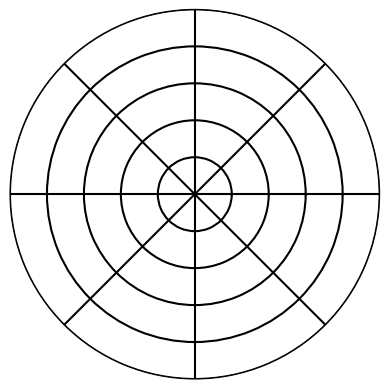

In [5]:
############################################################
# Photon-reaction data file
##############################

class photon_dat:
    def __init__( self ):
        self.f_sigma = sigma_pi(  );
        self.  cache =         {  };
        self.    cps = configparser.ConfigParser(  );
        self.    cps . optionxform = str
        return;
    #
    def lg_str( self, v ):
        return ' '.join( [ '%0.2f' % vs for vs in \
                           log10( array( v ) + 1e-32 ) ] );
    #
    def read_umist( self, basic_file ):
        with open( basic_file, 'r' ) as f:
            lines = f.readlines(  );
        for l in lines:
            if l.strip(  )[ 0 ] == '#':
                continue;
            ll    = l.split( ':' );
            reacs = [ 'PHOTON' if s in [ 'CRP', 'CRPHOT' ]
                      else s for s in ll[ 2 : 4 ] ];
            prods = [ '' if s == 'PHOTON'
                      else s for s in ll[ 4 : 8 ] ];
            if  not 'PHOTON' in reacs:
                continue;
            label = ' '.join(       reacs   ).strip(  );
            prods = ' '.join( sort( prods ) ).strip(  );
            if  not label in self.cache:
                self.cache[ label ] = {  };
            # if  prods in self.cache[ label ]:
            self.cache[ label ][ prods ]\
                    = { 'rate' : float ( ll[ 9 ] ) };
        #

        for label, paths in self.cache.items(  ):
            norm = 0;
            for prods,  dat in paths.items(  ):
                norm += dat[ 'rate' ] ;
            reac = label.split(  )[ 0 ];
            for prods in paths:
                self.cache[ label ][ prods ][ 'frac' ]\
                    = self.cache\
                      [ label ][ prods ][ 'rate' ] / norm
                if 'e-' in prods:
                    try:
                        hv, sig = self.f_sigma.\
                            get_sigma_table_sp( reac );
                        ene  = ( hv - hv.min(  ) ) * eV\
                             + 1e-32;
                        sig *= self. cache\
                            [ label ][ prods ][ 'frac' ];
                        self. cache[ label ][ prods ]\
                            [ 'comments' ] = 'Verner96'
                    except:
                        print( 'Skipping ', label, ' -> ',
                               prods );
                        continue;
                    #
                else:
                    hv  = array( [ 11, 13.6 ] );
                    sig = 1 / ( 9e7 ) * self.cache\
                        [ label ][ prods ][ 'rate' ]\
                        * ones( 2 );
                    # Habing flux eqiv. to 9e7 ph/cm^2/s
                    # Draine (2011) eq. (12.6)
                    # Lowest hv to 11 intentionally
                    ene = 1 * eV * ones( 2 );
                    self. cache[ label ][ prods ]\
                        [ 'comments' ] = 'UMIST/Habing'
                #   On average, 1 eV per reaction
                self.cache [ label ] [ prods ]\
                     [ 'lg_hv'     ] = self.lg_str(  hv );
                self.cache [ label ] [ prods ]\
                     [ 'lg_sigma'  ] = self.lg_str( sig );
                self.cache [ label ] [ prods ]\
                     [ 'lg_energy' ] = self.lg_str( ene );
                #
            #
        #        
        return;
    #
    def enroll_reac( self, reacs, prods,
                     hvs  = None, sigmas = None  ,
                     enes = None, multi  = None ):
        if  isinstance( reacs, str ):
            reacs =   [ reacs ];
        if  not 'PHOTON' in reacs:
            reacs.append( 'PHOTON' );
        if  isinstance( prods, str ):
            prods =   [ prods ];
        #
        prods = sort( prods );
        label = ' '.join( reacs );
        prodl = ' '.join( prods );
        if label in self.cache and \
           prodl in self.cache[ label ]:
            ldic =  self.cache[ label ][ prodl ];
        else:
            ldic = {  };
        #
        if hvs is not None:        
            ldic[ 'lg_hv'     ] = self.lg_str(    hvs );
        if sigmas is not None:
            ldic[ 'lg_sigma'  ] = self.lg_str( sigmas );
        if   enes is not None:
            ldic[ 'lg_energy' ] = self.lg_str(   enes );
        if  multi is not None:
            ldic[ 'lg_multi'  ] = self.lg_str(  multi );
        self.cache[ ' '.join( reacs ) ] \
                  [ ' '.join( prods ) ] = ldic;
        return;
    #
    def enroll_shield\
        ( self, reacs, prods, shield_sp, pars ):
        if  isinstance( reacs, str ):
            reacs =   [ reacs ];    
        if  not 'PHOTON' in reacs:
            reacs.append( 'PHOTON' );
        if  isinstance( prods, str ):
            prods =   [ prods ];
        label = ' '.join(       reacs   );
        prods = ' '.join( sort( prods ) );
        
        if  not label in self.cache  or\
            not prods in self.cache[ label ]:
            return;
        #

        try:
            aa = self.cache[ label ][ prods ];
        except:
            print( label, '\n', prods )
            print( self.cache[ label ] );
            raise ValueError
        #
        if  not 'shield_sps' in \
            self.cache[ label ][ prods ]:
            self.cache[ label ][ prods ][ 'shield_sps' ]\
                = '';
        #
        self.cache[ label ][ prods ][ 'shield_sps' ]\
            += shield_sp.strip(  ) + ' '
        self.cache[ label ][ prods ]\
            [ 'shield_par_' + shield_sp ] = ' '.join\
                ( [ '%0.2e' % p for p in pars ] );
        #
        return;
    #

    def write( self, file_name ):
        count = 0;
        for label in self.cache:
            for prods, l in self.cache[ label ].items(  ):
                l[ 'reactants ' ] = label;
                l[ 'products  ' ] = prods;
                if 'rate' in l:
                    del l[ 'rate' ];
                if 'frac' in l:
                    del l[ 'frac' ];
                #
                self.cps[ 'reaction_%03d' % count ] = l;
                count += 1;
            #
        #
        with open( file_name, 'w' ) as f:
            self.cps.write( f );        
    #
#

############################################################

In [18]:
############################################################
# Call the methods for photon reactions
##############################

pd = photon_dat(  );

pd . read_umist( 'RATE_K.txt' );
pd.enroll_reac( 'H2', [ 'H', 'H' ], [ 11.27, 13.6 ],
                6e-18 * ones( 2 ), enes = eV * ones( 2 ) );
# eq. (31.17) and below in Draine (2011)
# On average, each reaction injects 1 eV
pd.enroll_reac( 'OH',  [ 'O' , 'H' ], [ 4.5, 13.6 ] );
pd.enroll_reac( 'H2O', [ 'OH', 'H' ], [ 4.5, 13.6 ] );

pd.enroll_reac( 'N2', [ 'N2+', 'e-' ] );


##############################
# Enroll fitted shielding


pd.enroll_shield( 'C', [ 'C+', 'e-' ], 'C',
                  ( 5.64e+16, 9.85e-01, 1.00e+00 ,
                    5.15e+17, 8.98e-01, 2.69e-05 ) );
pd.enroll_shield( 'C', [ 'C+', 'e-' ], 'H2',
                  ( 5.87e21, 6.88e-1, 1.00e0 ,
                    5.87e21, 6.88e-1, 0.00e0 ) );

pd.enroll_shield( 'S', [ 'S+', 'e-' ], 'S',
                  ( 8.17e+15, 3.91e-01, 1.00e+00 ,
                    6.76e+18, 8.73e-01, 1.83e-04 ) );
pd.enroll_shield( 'S', [ 'S+', 'e-' ], 'H2',
                  ( 1.41e+21, 4.19e-01, 6.33e-01 ,
                    2.22e+24, 8.79e-01, 3.67e-01 ) );
pd.enroll_shield( 'S', [ 'S+', 'e-' ], 'C',
                  ( 5.78e+16,  9.64e-01, 6.05e-01 ,
                    1.15e+23,  5.13e-01, 3.95e-01 ) );

pd.enroll_shield( 'Si', [ 'Si+', 'e-' ], 'Si',
                  ( 1.49e+16, 8.30e-01, 0.99e+00 ,
                    6.87e+16, 7.31e-01, 4.02e-03 ) );

pd.enroll_shield( 'SiO', [ 'Si', 'O' ], 'SiO',
                  ( 9.98e+15, 5.10e-01, 1.00e+00 ,
                    1.67e+19, 9.44e-01, 5.69e-03 ) );
pd.enroll_shield( 'SiO', [ 'Si', 'O' ], 'H2',
                  ( 2.05e+20, 5.58e-01, 1.00e-00 ,
                    2.05e+20, 5.58e-01, 0.00e-00 ) );

pd.enroll_shield( 'CO', [ 'C', 'O' ], 'CO',
                  ( 1.14e+11, 1.28e-01, 7.80e+00 ,
                    3.78e+20, 6.51e-01, 9.39e-05 ) );
pd.enroll_shield( 'CO', [ 'C', 'O' ], 'C',
                  ( 5.82e+16, 9.99e-01, 1.00e00 ,
                    5.82e+16, 9.99e-01, 0.00e00 ) );
pd.enroll_shield( 'CO', [ 'C', 'O' ], 'H2',
                  ( 6.76e+20, 6.45e-01, 1.00e00 ,
                    6.76e+20, 6.45e-01, 0.00e00 ) );

##############################
# Output

pd.write( 'photon_reac.dat' );

############################################################

In [19]:
############################################################
# Multiplier for secondary X-ray ionization
##############################

# Using [ 1 + ( hv - I ) / I ] for the multiplier
# multis = [ [ 'H',  'H+ e-',   1 ],
#            [ 'H2', 'H2+ e-',  1 ],
#            [ 'H2', 'H H+ e-', 1 ],           
#            [ 'He', 'He+ e-',  1 ],
#           ];

# With "up-scattered" secondary electrons
multis = [ [ 'H',  'H+ e-',   20 ],
           [ 'H2', 'H2+ e-',  20 ],
           [ 'H2', 'H H+ e-',  1 ],           
           [ 'He', 'He+ e-',  20 ],
           [ 'O',  'O+ e-',   20 ],
           [ 'O2', 'O2+ e-',  20 ],
           [ 'N',  'N+ e-',   20 ],
           # [ 'N2', 'N2+ e-',  20 ],
          ];

hv_heat = 100;
for multi in multis:
    reac, prods, fac = multi;
    hvs  = [ 10**float( lghv ) for lghv in \
             pd.cache[ reac + ' PHOTON' ][ prods ]\
             [ 'lg_hv' ].split(  ) ];
    enes = [ 10**float( lge ) for lge in \
             pd.cache[ reac + ' PHOTON' ][ prods ]\
             [ 'lg_energy' ].split(  ) ];
    for i, hv in enumerate( hvs ):
        enes[ i ] *= ( hv < hv_heat ) ;
    mult = array( [ 1 + ( hv - hvs[ 0 ] ) / hvs[ 0 ]
                    for hv in hvs ] ) * fac;
    pd.enroll_reac( reac, prods, hvs, multi = mult );
#
pd.write( 'photon_reac.dat' );
############################################################